# Lab Task 03 — Image Enhancement and Intensity Transformations
**Digital Image Processing Lab** · Department of Software Engineering, University of Azad Jammu and Kashmir

**Name:** Raja Afzal  **Roll No:** 2024-SE-25  **Semester:** Fifth  **Session:** 2024-28 (SE)

## 0. Setup and image validation
The lab requires an **8-bit grayscale** image, so the colour photo is converted to grayscale while loading (`cv.IMREAD_GRAYSCALE`). Every task below is performed on this grayscale version; the colour original is displayed once for reference. The grayscale array `img` is kept read-only so the original is never modified.

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# my selected image (JPG, 640 x 427)
IMAGE_PATH = "parrot.jpg"   

def show(images, titles, figsize=None, cols=None):
    """Display images side by side with the fixed grayscale range 0-255."""
    n = len(images)
    cols = cols or n
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=figsize or (4.2 * cols, 4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def table(headers, rows, width=14):
    """Print a simple text table (used for all dry runs)."""
    print("".join(str(h).ljust(width) for h in headers))
    print("-" * width * len(headers))
    for r in rows:
        print("".join(str(c).ljust(width) for c in r))

shape: (427, 640) | dtype: uint8 | min: 0 | max: 255


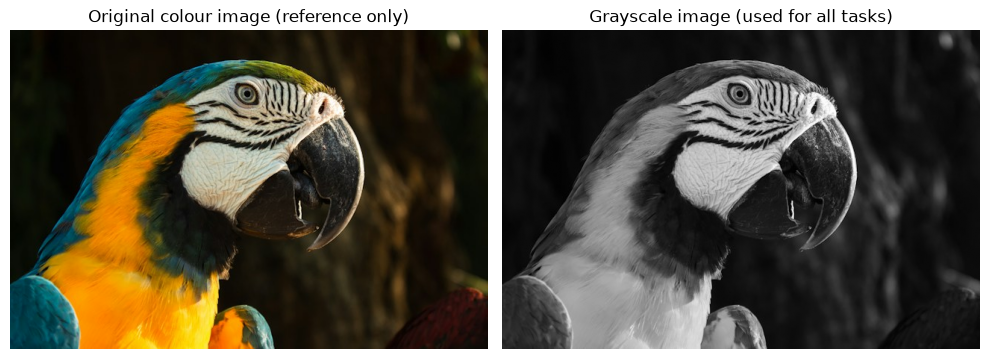

In [ ]:
# 8-bit grayscale
img = cv.imread(IMAGE_PATH, cv.IMREAD_GRAYSCALE)      
if img is None:
    raise FileNotFoundError(f"Could not read {IMAGE_PATH}. Put your image next to the notebook.")
assert img.dtype == np.uint8 and img.ndim == 2, "Expected an 8-bit grayscale image"
assert img.shape[0] >= 300 and img.shape[1] >= 300, "Image must be at least 300 x 300"

# the original can no longer be modified by accident
img.flags.writeable = False      
print("shape:", img.shape, "| dtype:", img.dtype, "| min:", img.min(), "| max:", img.max())

# colour original, shown for reference only
color_bgr = cv.imread(IMAGE_PATH, cv.IMREAD_COLOR)    
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv.cvtColor(color_bgr, cv.COLOR_BGR2RGB))
axes[0].set_title("Original colour image (reference only)")
axes[1].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale image (used for all tasks)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Numeric safety (why we widen types and clip)
`uint8` arithmetic **wraps around** (overflow): 200 + 100 = 300 becomes 300 − 256 = **44**, which turns a bright pixel dark.
So every transformation below is computed in a wider type (`int16` / `float32`), then **clipped to 0–255** and only then converted to `uint8`.
Converting float → `uint8` with `astype` **truncates** the fraction (e.g. 127.75 → 127).

In [29]:
a = np.array([200, 250], dtype=np.uint8)
print("uint8 overflow  :", a + 100)                                   # wraps around
print("safe (int16+clip):", np.clip(a.astype(np.int16) + 100, 0, 255).astype(np.uint8))

uint8 overflow  : [44 94]
safe (int16+clip): [255 255]


## 1. Brightness adjustment  (β = +40 and −40)

### Dry run 1 — pixels [30, 80, 128, 180, 240]

In [30]:
px = np.array([30, 80, 128, 180, 240])
rows = []
for r in px:
    up_raw, dn_raw = r + 40, r - 40
    rows.append([r, up_raw, min(255, max(0, up_raw)), dn_raw, min(255, max(0, dn_raw))])
table(["r", "r+40 (raw)", "clipped", "r-40 (raw)", "clipped"], rows)

# Python verification with the same safe pipeline used on the image
print("verify +40:", np.clip(px.astype(np.int16) + 40, 0, 255).astype(np.uint8))
print("verify -40:", np.clip(px.astype(np.int16) - 40, 0, 255).astype(np.uint8))

r             r+40 (raw)    clipped       r-40 (raw)    clipped       
----------------------------------------------------------------------
30            70            70            -10           0             
80            120           120           40            40            
128           168           168           88            88            
180           220           220           140           140           
240           280           255           200           200           
verify +40: [ 70 120 168 220 255]
verify -40: [  0  40  88 140 200]


**Lost detail:** 240 + 40 = 280 → 255 (clipped), and 30 − 40 = −10 → 0 (clipped). Clipping is many-to-one: any pixel above 215 becomes 255 after +40
(so 216 and 240 become identical), and any pixel below 40 becomes 0 after −40. Once clipped, the original differences cannot be recovered.

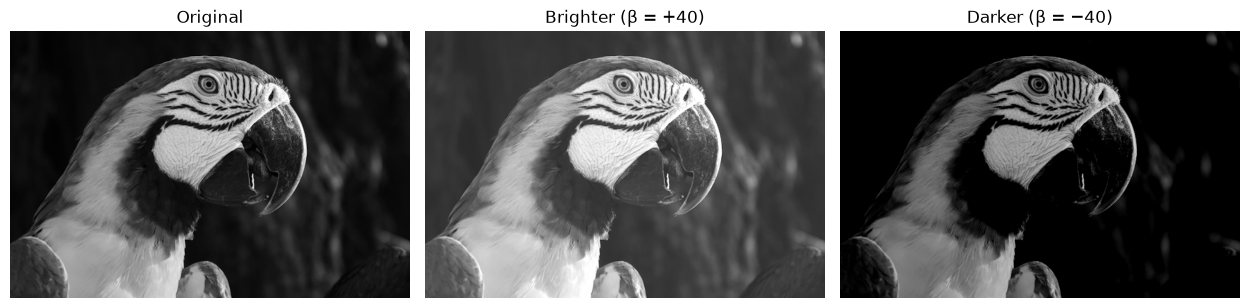

In [31]:
bright = np.clip(img.astype(np.int16) + 40, 0, 255).astype(np.uint8)
dark   = np.clip(img.astype(np.int16) - 40, 0, 255).astype(np.uint8)
show([img, bright, dark], ["Original", "Brighter (β = +40)", "Darker (β = −40)"])

In [32]:
# +40 with nested loops, verified against the NumPy result
h, w = img.shape
bright_loop = np.zeros_like(img)
for row in range(h):
    for col in range(w):
        value = int(img[row, col]) + 40          # Python int: no uint8 overflow
        bright_loop[row, col] = min(255, max(0, value))

print("Nested-loop result identical to NumPy result:", np.array_equal(bright_loop, bright))

Nested-loop result identical to NumPy result: True


## 2. Linear contrast from zero  (s = αr + β, α = 1.5, β = 0)

### Dry run 2 — pixels [30, 80, 128, 180, 240]

In [33]:
rows = []
for r in px:
    raw = 1.5 * r
    clipped = min(255, max(0, raw))
    rows.append([r, raw, clipped, int(clipped), "SATURATED" if raw > 255 else ""])
table(["r", "1.5*r", "clipped", "truncated", "note"], rows)
print("verify:", np.clip(1.5 * px.astype(np.float32), 0, 255).astype(np.uint8))

r             1.5*r         clipped       truncated     note          
----------------------------------------------------------------------
30            45.0          45.0          45                          
80            120.0         120.0         120                         
128           192.0         192.0         192                         
180           270.0         255           255           SATURATED     
240           360.0         255           255           SATURATED     
verify: [ 45 120 192 255 255]


Pixels 180 (270) and 240 (360) exceed 255 and saturate to 255, so they become indistinguishable. Because the scaling starts from 0,
the whole image also gets **brighter**, not only more contrasty — dark values move little, bright values move a lot.

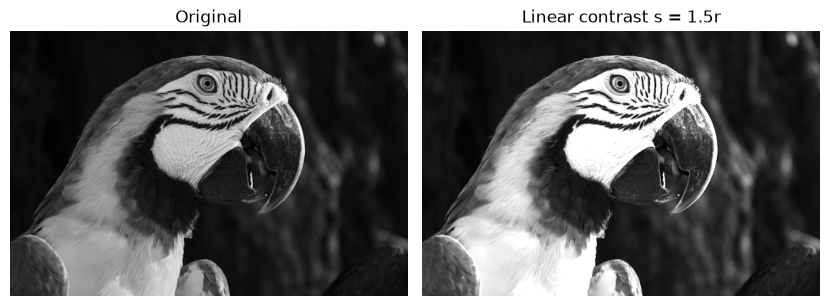

Mean brightness  original: 57.54 | 1.5r: 83.3
Saturated (==255) pixels original: 83 | 1.5r: 20812 (7.62% of the image)


In [34]:
alpha, beta = 1.5, 0
lin = np.clip(alpha * img.astype(np.float32) + beta, 0, 255).astype(np.uint8)
show([img, lin], ["Original", "Linear contrast s = 1.5r"])

print("Mean brightness  original:", round(img.mean(), 2), "| 1.5r:", round(lin.mean(), 2))
print("Saturated (==255) pixels original:", int((img == 255).sum()),
      "| 1.5r:", int((lin == 255).sum()),
      f"({100 * (lin == 255).mean():.2f}% of the image)")

## 3. Contrast centred at 128  (s = (r − 128)α + 128, α = 1.5 and 0.5)

### Dry run 3 — pixels [30, 80, 128, 180, 240]

In [35]:
rows = []
for r in px:
    row = [r, r - 128]
    for a in (1.5, 0.5):
        raw = (r - 128) * a + 128
        row += [raw, int(min(255, max(0, raw)))]
    rows.append(row)
table(["r", "r-128", "a=1.5 raw", "a=1.5 final", "a=0.5 raw", "a=0.5 final"], rows, width=15)

for a in (1.5, 0.5):
    out = np.clip((px.astype(np.float32) - 128) * a + 128, 0, 255).astype(np.uint8)
    print(f"verify alpha={a}:", out)

r              r-128          a=1.5 raw      a=1.5 final    a=0.5 raw      a=0.5 final    
------------------------------------------------------------------------------------------
30             -98            -19.0          0              79.0           79             
80             -48            56.0           56             104.0          104            
128            0              128.0          128            128.0          128            
180            52             206.0          206            154.0          154            
240            112            296.0          255            184.0          184            
verify alpha=1.5: [  0  56 128 206 255]
verify alpha=0.5: [ 79 104 128 154 184]


At r = 128 the term (r − 128) is 0, so s = 128 for **every** α — the pivot (mid-gray) never moves.
α = 1.5 pushes values away from 128 (30 → −19 → clipped to 0, 240 → 296 → clipped to 255); α = 0.5 pulls them toward 128 and reduces contrast.

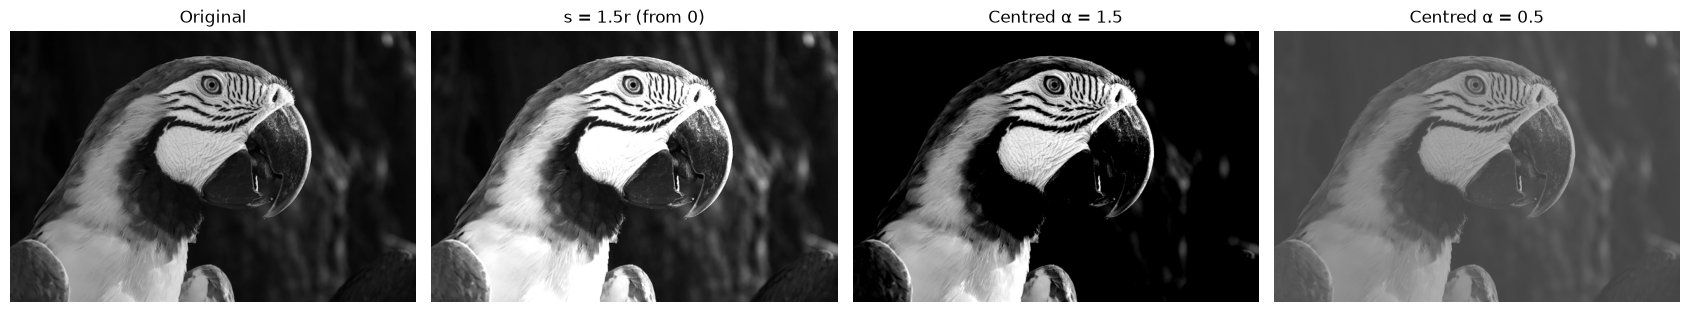

Original     mean =  57.54  std =  60.25
1.5r         mean =  83.30  std =  84.10
centred 1.5  mean =  44.34  std =  75.03
centred 0.5  mean =  92.52  std =  30.13


In [36]:
c15 = np.clip((img.astype(np.float32) - 128) * 1.5 + 128, 0, 255).astype(np.uint8)
c05 = np.clip((img.astype(np.float32) - 128) * 0.5 + 128, 0, 255).astype(np.uint8)
show([img, lin, c15, c05],
     ["Original", "s = 1.5r (from 0)", "Centred α = 1.5", "Centred α = 0.5"], cols=4, figsize=(17, 4.2))
for name, im in [("Original", img), ("1.5r", lin), ("centred 1.5", c15), ("centred 0.5", c05)]:
    print(f"{name:12s} mean = {im.mean():6.2f}  std = {im.std():6.2f}")

## 4. Image negative  (s = 255 − r)

### Dry run 4 — pixels [30, 80, 128, 180, 240]

In [37]:
neg_px = 255 - px
again  = 255 - neg_px
table(["r", "255-r", "255-(255-r)", "same as original?"],
      [[r, n, a, bool(r == a)] for r, n, a in zip(px, neg_px, again)])

r             255-r         255-(255-r)   same as original?
--------------------------------------------------------
30            225           30            True          
80            175           80            True          
128           127           128           True          
180           75            180           True          
240           15            240           True          


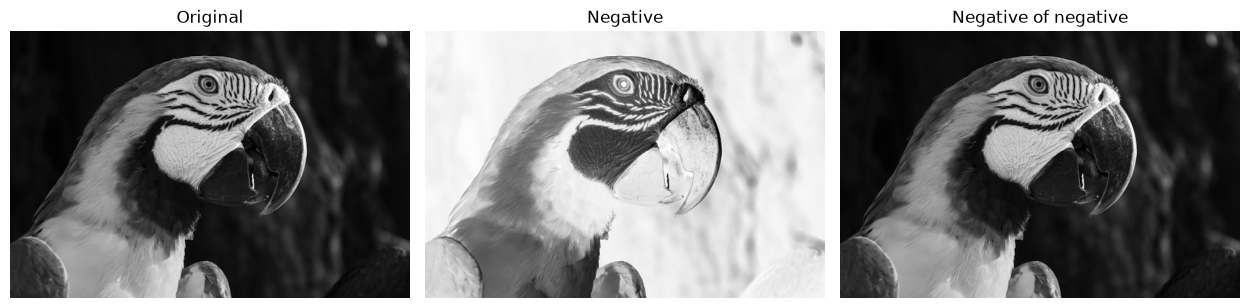

Double negative equals original: True


In [38]:
negative = (255 - img.astype(np.int16)).astype(np.uint8)
show([img, negative, (255 - negative.astype(np.int16)).astype(np.uint8)],
     ["Original", "Negative", "Negative of negative"])
print("Double negative equals original:", np.array_equal(255 - negative, img))

**Inspection example:** in medical/X-ray or scanned-document images, faint bright details (small bright lesions, light pencil marks) can be easier to see
on a dark-on-light display, and fine white structures in dark regions become dark structures in light regions.
Applying the negative twice returns the original exactly, so no information is lost.

## 5. Gamma correction  (s = 255 (r/255)^γ, γ = 0.5 and 2.0)

### Dry run 5 — pixels [0, 64, 128, 192, 255]

In [39]:
gp = np.array([0, 64, 128, 192, 255])
for g in (0.5, 2.0):
    print(f"\n--- gamma = {g} ---")
    rows = []
    for r in gp:
        norm  = r / 255              # normalisation
        power = norm ** g            # power (full precision)
        scaled = 255 * power         # scaling
        rows.append([r, f"{norm:.6f}", f"{power:.6f}", f"{scaled:.4f}", int(scaled)])   # truncate only at the end
    table(["r", "r/255", "(r/255)^g", "x255", "final"], rows, width=13)
    print("verify:", np.clip(255 * (gp / 255) ** g, 0, 255).astype(np.uint8))


--- gamma = 0.5 ---
r            r/255        (r/255)^g    x255         final        
-----------------------------------------------------------------
0            0.000000     0.000000     0.0000       0            
64           0.250980     0.500979     127.7498     127          
128          0.501961     0.708492     180.6654     180          
192          0.752941     0.867722     221.2691     221          
255          1.000000     1.000000     255.0000     255          
verify: [  0 127 180 221 255]

--- gamma = 2.0 ---
r            r/255        (r/255)^g    x255         final        
-----------------------------------------------------------------
0            0.000000     0.000000     0.0000       0            
64           0.250980     0.062991     16.0627      16           
128          0.501961     0.251965     64.2510      64           
192          0.752941     0.566920     144.5647     144          
255          1.000000     1.000000     255.0000     255          
veri

**Difference from the slide example:** the slide rounds intermediate values (e.g. r/255 ≈ 0.25, √0.25 = 0.5 → 127.5, so it shows 128 or 127/128).
Here the full-precision value (r = 64, γ = 0.5 → 127.7498) is kept and **truncated** at the very end, giving 127. Rounding early or rounding vs truncating
gives answers that differ by 1 gray level — both are valid, but the lab asks for full precision with a final truncation.

Gamma convention used here: output = 255 (r/255)^γ. **γ < 1 brightens** (lifts dark regions), **γ > 1 darkens**.

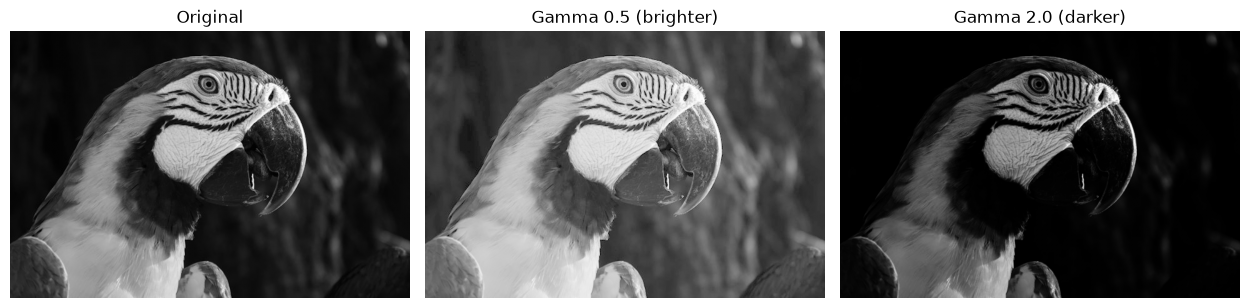

gamma 0.5 on [0,255]: [  0 255] | gamma 2.0 on [0,255]: [  0 255]
Mean of originally dark pixels (<64): original = 22.8 | g=0.5 -> 72.2 | g=2.0 -> 2.4


In [40]:
def gamma_correct(image, g):
    return np.clip(255 * np.power(image.astype(np.float32) / 255, g), 0, 255).astype(np.uint8)

g05, g20 = gamma_correct(img, 0.5), gamma_correct(img, 2.0)
show([img, g05, g20], ["Original", "Gamma 0.5 (brighter)", "Gamma 2.0 (darker)"])

# 0 and 255 must stay fixed
ends = np.array([0, 255], dtype=np.uint8)
print("gamma 0.5 on [0,255]:", gamma_correct(ends, 0.5), "| gamma 2.0 on [0,255]:", gamma_correct(ends, 2.0))

# effect on dark regions
dark_mask = img < 64
print("Mean of originally dark pixels (<64): original =", round(img[dark_mask].mean(), 1),
      "| g=0.5 ->", round(g05[dark_mask].mean(), 1), "| g=2.0 ->", round(g20[dark_mask].mean(), 1))

## 6. Grayscale histogram

### Dry run 6 — A = [[0, 50, 50, 100], [100, 150, 200, 255]]

In [41]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]], dtype=np.uint8)
total = A.size
vals, counts = np.unique(A, return_counts=True)
table(["intensity", "frequency", "probability"], [[v, c, f"{c}/{total} = {c/total:.3f}"] for v, c in zip(vals, counts)], width=18)
print("total pixels:", total, "| sum of frequencies:", counts.sum(), "| sum of probabilities:", (counts / total).sum())

# the histogram is identical for any rearrangement of the pixels
shuffled = A.ravel()[::-1].reshape(A.shape)
print("Same histogram after rearranging pixels:",
      np.array_equal(np.bincount(A.ravel(), minlength=256), np.bincount(shuffled.ravel(), minlength=256)))

intensity         frequency         probability       
------------------------------------------------------
0                 1                 1/8 = 0.125       
50                2                 2/8 = 0.250       
100               2                 2/8 = 0.250       
150               1                 1/8 = 0.125       
200               1                 1/8 = 0.125       
255               1                 1/8 = 0.125       
total pixels: 8 | sum of frequencies: 8 | sum of probabilities: 1.0
Same histogram after rearranging pixels: True


A histogram only **counts** how many pixels have each intensity; it throws away *where* they are. Two completely different pictures
(or the same picture with its pixels shuffled) can have exactly the same histogram.

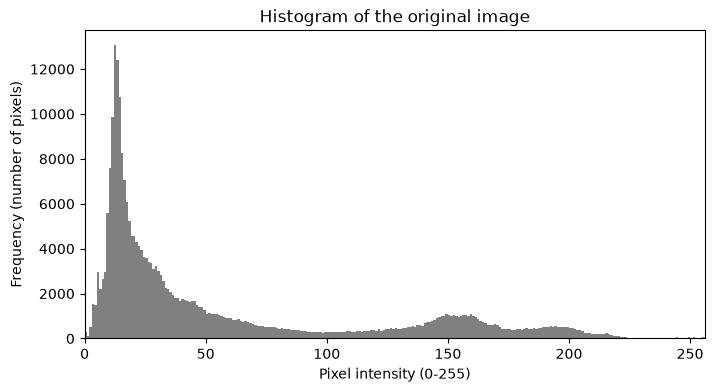

mean = 57.5, std = 60.3, min = 0, max = 255
dark (<85): 75.3%  mid (85-170): 17.3%  bright (>170): 7.4%


In [42]:
plt.figure(figsize=(8, 4))
plt.hist(img.ravel(), bins=256, range=(0, 256), color="gray")
plt.xlabel("Pixel intensity (0-255)")
plt.ylabel("Frequency (number of pixels)")
plt.title("Histogram of the original image")
plt.xlim(0, 256)
plt.show()

print(f"mean = {img.mean():.1f}, std = {img.std():.1f}, min = {img.min()}, max = {img.max()}")
print(f"dark (<85): {100*(img<85).mean():.1f}%  mid (85-170): {100*((img>=85)&(img<=170)).mean():.1f}%  bright (>170): {100*(img>170).mean():.1f}%")

**Interpretation:** The histogram is heavily skewed to the left: about 75% of the pixels are darker than 85 (mean ≈ 57.5), because the background is dark, and only about 7% are brighter than 170, coming from the white face patch and the yellow/orange feathers. The spread is moderate (std ≈ 60) with a tall mass in the shadows and a thin tail toward 255, and almost no pixels sit exactly at 0 or 255 (≈ 0.1% and ≈ 0.03%), so there is very little clipping in the original.

## 7. Global histogram equalization  (`cv2.equalizeHist`)

### Dry run 7 — pixels [50, 50, 100, 150]

In [43]:
p7 = np.array([50, 50, 100, 150], dtype=np.uint8)
N = p7.size
levels, freq = np.unique(p7, return_counts=True)
cum  = np.cumsum(freq)
cdf  = cum / N
cdf_min = cdf[cdf > 0].min()

def round_half_up(x):
    return int(np.floor(x + 0.5))

table(["intensity", "freq", "cumulative", "CDF"], [[l, f, c, d] for l, f, c, d in zip(levels, freq, cum, cdf)])
print("CDF min =", cdf_min)

map1 = [round_half_up(255 * d) for d in cdf]
map2 = [round_half_up(255 * (d - cdf_min) / (1 - cdf_min)) for d in cdf]
print("\nMapping 1  255*CDF                      :", dict(zip(levels.tolist(), map1)))
print("Mapping 2  255*(CDF-CDFmin)/(1-CDFmin) :", dict(zip(levels.tolist(), map2)))

lut1 = dict(zip(levels.tolist(), map1)); lut2 = dict(zip(levels.tolist(), map2))
print("\nOutput list (mapping 1):", [lut1[v] for v in p7.tolist()])
print("Output list (mapping 2):", [lut2[v] for v in p7.tolist()])

cv_out = cv.equalizeHist(p7.reshape(2, 2)).ravel().tolist()    # equalizeHist needs a 2-D 8-bit image
print("OpenCV equalizeHist    :", cv_out)
print("Mapping 2 matches OpenCV:", cv_out == [lut2[v] for v in p7.tolist()])

intensity     freq          cumulative    CDF           
--------------------------------------------------------
50            2             2             0.5           
100           1             3             0.75          
150           1             4             1.0           
CDF min = 0.5

Mapping 1  255*CDF                      : {50: 128, 100: 191, 150: 255}
Mapping 2  255*(CDF-CDFmin)/(1-CDFmin) : {50: 0, 100: 128, 150: 255}

Output list (mapping 1): [128, 128, 191, 255]
Output list (mapping 2): [0, 0, 128, 255]
OpenCV equalizeHist    : [0, 0, 128, 255]
Mapping 2 matches OpenCV: True


Mapping 1 never sends the darkest present level to 0 (50 → 128). Mapping 2 subtracts CDFmin so the darkest present level goes to 0 and the brightest to 255,
using the full range — this is the formula OpenCV uses.

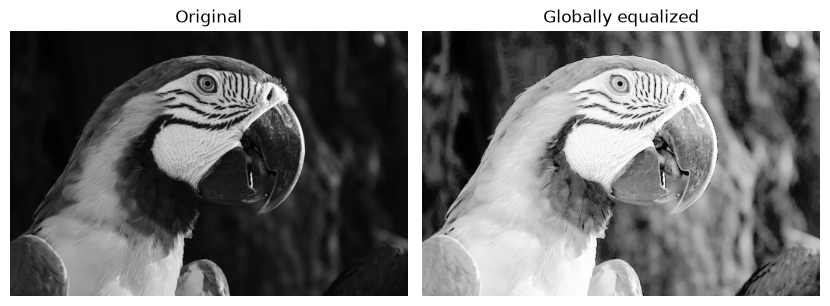

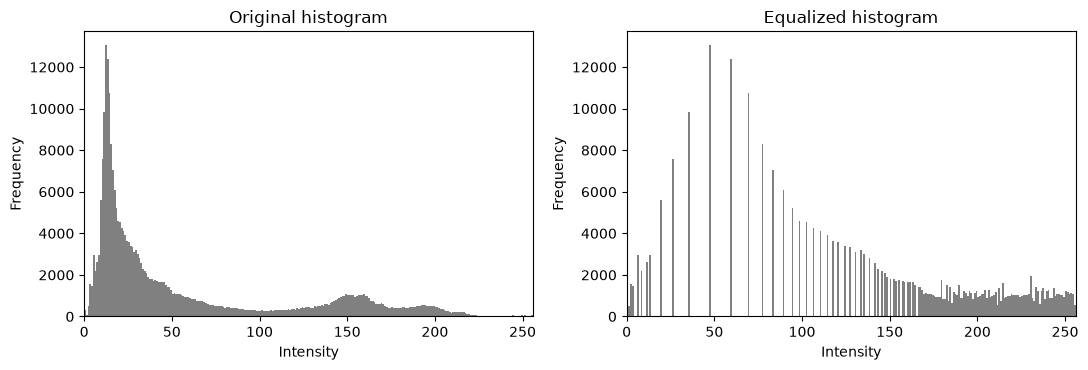

std: 60.3 -> 72.3   |  Laplacian variance (detail + noise proxy): 533.4 -> 1413.3


In [44]:
equalized = cv.equalizeHist(img)
show([img, equalized], ["Original", "Globally equalized"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, im, t in zip(axes, [img, equalized], ["Original histogram", "Equalized histogram"]):
    ax.hist(im.ravel(), bins=256, range=(0, 256), color="gray")
    ax.set_title(t); ax.set_xlabel("Intensity"); ax.set_ylabel("Frequency"); ax.set_xlim(0, 256)
plt.tight_layout(); plt.show()

lap = lambda im: cv.Laplacian(im, cv.CV_64F).var()
print(f"std: {img.std():.1f} -> {equalized.std():.1f}   |  Laplacian variance (detail + noise proxy): {lap(img):.1f} -> {lap(equalized):.1f}")

**Discussion:** Equalization spreads the histogram over 0–255 (std 60.3 → 72.3). Detail clearly improves in the dark background, where the bark and foliage texture becomes visible, and the face and chest become brighter.
However, the Laplacian variance rises from about 533 to about 1413, showing that fine texture and noise are both amplified; the background looks blotchy, and the bright chest and face regions look slightly washed out. Because the mapping is global, the large dark area dominates the result.

## 8. CLAHE  (`clipLimit = 2.0`, `tileGridSize = (8, 8)`)

### Dry run 8 — histogram [6, 2, 0, 0], absolute cap = 4

In [45]:
hist = np.array([6, 2, 0, 0], dtype=float)
cap = 4
clipped = np.minimum(hist, cap)
excess = (hist - clipped).sum()
share = excess / len(hist)
new_hist = clipped + share

print("original hist :", hist, "| total =", hist.sum())
print("after clip    :", clipped, "| excess =", excess)
print("add excess/4  :", share, "to every bin ->", new_hist, "| total =", new_hist.sum())

cum_new = np.cumsum(new_hist)
cdf_new = cum_new / new_hist.sum()
cdf_old = np.cumsum(hist) / hist.sum()
table(["bin", "old CDF", "new cum", "new CDF", "255*new CDF"],
      [[i, round(o, 4), c, round(n, 4), round(255 * n, 2)] for i, (o, c, n) in enumerate(zip(cdf_old, cum_new, cdf_new))], width=13)

original hist : [6. 2. 0. 0.] | total = 8.0
after clip    : [4. 2. 0. 0.] | excess = 2.0
add excess/4  : 0.5 to every bin -> [4.5 2.5 0.5 0.5] | total = 8.0
bin          old CDF      new cum      new CDF      255*new CDF  
-----------------------------------------------------------------
0            0.75         4.5          0.5625       143.44       
1            1.0          7.0          0.875        223.12       
2            1.0          7.5          0.9375       239.06       
3            1.0          8.0          1.0          255.0        


Clipping stops the tall bin (6) from dominating, so the mapping curve is gentler and noise is not over-amplified. The CDF becomes 0.5625, 0.875, 0.9375, 1.0 instead of 0.75, 1, 1, 1.

**Why interpolation is needed:** CLAHE builds a *separate* mapping for every tile. Pixels near a tile border would jump visibly if each tile's mapping were applied alone,
so each pixel's output is **bilinearly interpolated** from the mappings of the neighbouring tiles. (This simplified model differs from OpenCV's integer redistribution,
and the absolute cap of 4 is not the same thing as OpenCV's `clipLimit` parameter.)

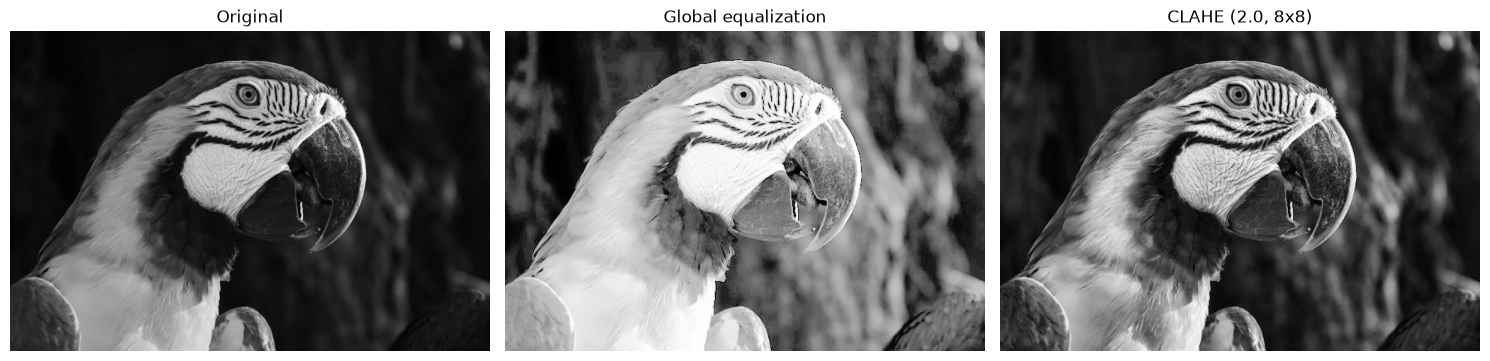

tileGridSize=(8, 8) means an 8 x 8 GRID of tiles (64 tiles), not 8x8 pixels per tile.
For this 427x640 image each tile is about 53 x 80 pixels.


In [46]:
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced = clahe.apply(img)
show([img, equalized, enhanced], ["Original", "Global equalization", "CLAHE (2.0, 8x8)"], figsize=(15, 4.4))

h, w = img.shape
print(f"tileGridSize=(8, 8) means an 8 x 8 GRID of tiles (64 tiles), not 8x8 pixels per tile.")
print(f"For this {h}x{w} image each tile is about {h//8} x {w//8} pixels.")

**Comparison:** Global equalization uses one curve for the whole image, so the large dark background pushes the whole picture brighter and the face looks flat and washed out. CLAHE works per tile, so the lit face and feathers keep their local contrast (the stripes around the eye and the white patch stay crisp) while the dark background is lifted only moderately, with less noise amplification. The image has uneven lighting (a bright bird on a dark background), which is exactly where CLAHE is expected to look more natural than global equalization.

## 9. Fixed binary thresholding  (T = 127)

### Dry run 9 — pixels [0, 80, 127, 128, 180, 255]

In [47]:
p9 = [0, 80, 127, 128, 180, 255]
rows = []
for r in p9:
    rows.append([r, 255 if r > 127 else 0, 255 if r > 180 else 0])
table(["r", "T=127 out", "T=180 out"], rows)
w127 = sum(1 for r in p9 if r > 127); w180 = sum(1 for r in p9 if r > 180)
print("white pixels  T=127:", w127, "| T=180:", w180)

arr = np.array([p9], dtype=np.uint8)
print("verify T=127:", cv.threshold(arr, 127, 255, cv.THRESH_BINARY)[1].ravel())
print("verify T=180:", cv.threshold(arr, 180, 255, cv.THRESH_BINARY)[1].ravel())

r             T=127 out     T=180 out     
------------------------------------------
0             0             0             
80            0             0             
127           0             0             
128           255           0             
180           255           0             
255           255           255           
white pixels  T=127: 3 | T=180: 1
verify T=127: [  0   0   0 255 255 255]
verify T=180: [  0   0   0   0   0 255]


Rule is `r > T`, so 127 (equal to T) stays black and 128 turns white. Raising T to 180 leaves fewer white pixels (1 instead of 3).

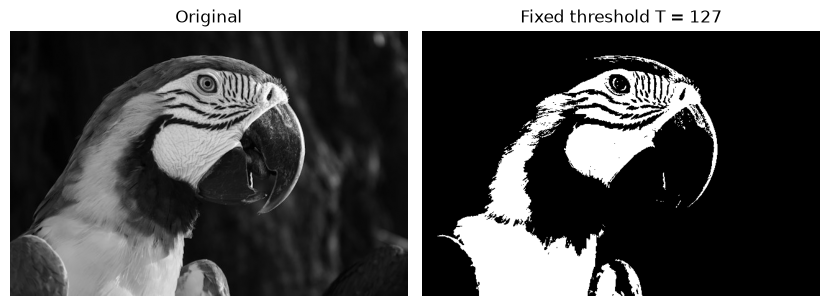

Threshold used: 127.0 | unique output values: [  0 255]
White pixels: 19.5%


In [48]:
T_fixed, binary = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
show([img, binary], ["Original", "Fixed threshold T = 127"])
print("Threshold used:", T_fixed, "| unique output values:", np.unique(binary))
print(f"White pixels: {100 * (binary == 255).mean():.1f}%")

## 10. Otsu thresholding

### Dry run 10 — pixels [0, 1, 4, 5] (no rescaling)

In [49]:
p10 = np.array([0, 1, 4, 5])
rows, best_T, best_val = [], None, -1
for T in range(0, 5):
    c0, c1 = p10[p10 <= T], p10[p10 > T]
    w0, w1 = len(c0) / len(p10), len(c1) / len(p10)
    m0, m1 = c0.mean(), c1.mean()
    sb = w0 * w1 * (m0 - m1) ** 2                     # between-class variance
    rows.append([T, f"{c0.tolist()}|{c1.tolist()}", f"{w0:.2f}/{w1:.2f}", f"{m0:.3f}/{m1:.3f}", round(sb, 4)])
    if sb > best_val + 1e-12:                           # strict '>' keeps the SMALLEST T among ties
        best_val, best_T = sb, T
table(["T", "class0 | class1", "w0/w1", "mu0/mu1", "w0w1(mu0-mu1)^2"], rows, width=20)
print("Best T (smallest among ties):", best_T, "| between-class variance =", best_val)

pred_mask = np.where(p10 > best_T, 255, 0)
ocv_T, ocv_mask = cv.threshold(p10.astype(np.uint8).reshape(1, -1), 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("Predicted mask:", pred_mask.tolist(), "| OpenCV threshold:", ocv_T, "| OpenCV mask:", ocv_mask.ravel().tolist())
print("Prediction matches OpenCV:", pred_mask.tolist() == ocv_mask.ravel().tolist())

T                   class0 | class1     w0/w1               mu0/mu1             w0w1(mu0-mu1)^2     
----------------------------------------------------------------------------------------------------
0                   [0]|[1, 4, 5]       0.25/0.75           0.000/3.333         2.0833              
1                   [0, 1]|[4, 5]       0.50/0.50           0.500/4.500         4.0                 
2                   [0, 1]|[4, 5]       0.50/0.50           0.500/4.500         4.0                 
3                   [0, 1]|[4, 5]       0.50/0.50           0.500/4.500         4.0                 
4                   [0, 1, 4]|[5]       0.75/0.25           1.667/5.000         2.0833              
Best T (smallest among ties): 1 | between-class variance = 4.0
Predicted mask: [0, 0, 255, 255] | OpenCV threshold: 1.0 | OpenCV mask: [0, 0, 255, 255]
Prediction matches OpenCV: True


T = 1, 2 and 3 tie (all give 4.0) because there are no pixels with values 2 or 3; the smallest, T = 1, is chosen. Pixels ≤ 1 → 0, pixels > 1 → 255.

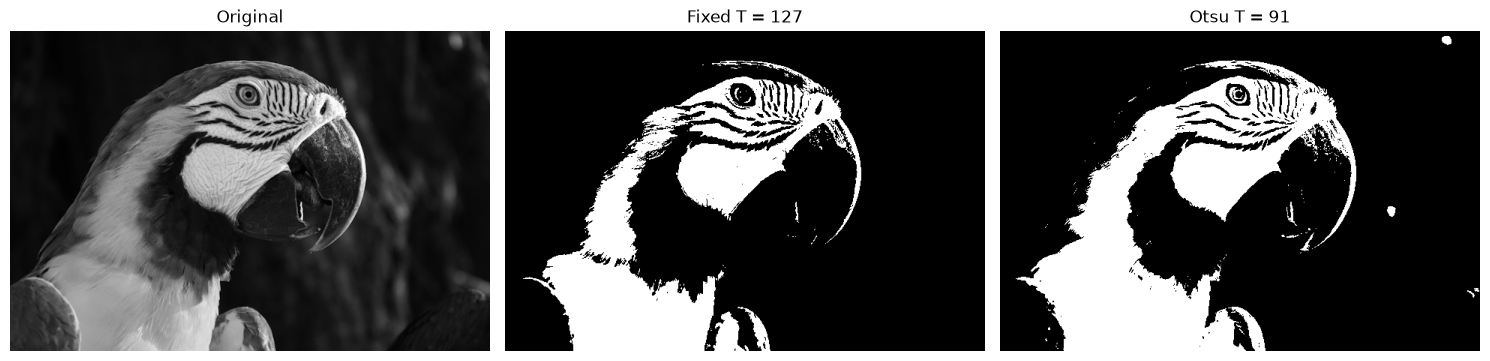

Otsu threshold returned by OpenCV: 91.0
Pixels where the two masks differ: 4.31%
White pixels  fixed: 19.5%  Otsu: 23.8%


In [50]:
T_otsu, otsu = cv.threshold(img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
show([img, binary, otsu], ["Original", "Fixed T = 127", f"Otsu T = {T_otsu:.0f}"], figsize=(15, 4.4))
print("Otsu threshold returned by OpenCV:", T_otsu)
diff = (binary != otsu)
print(f"Pixels where the two masks differ: {100 * diff.mean():.2f}%")
print(f"White pixels  fixed: {100*(binary==255).mean():.1f}%  Otsu: {100*(otsu==255).mean():.1f}%")

## 11. Adaptive Gaussian thresholding  (blockSize = 11, C = 2)

### Dry run 11 — 3 × 3 neighbourhood

In [51]:
nb = np.array([[100, 100, 100], [100, 120, 140], [140, 140, 140]], dtype=float)
wts = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16

products = nb * wts
print("weighted values:\n", products)
mean = products.sum()
Tloc = mean - 2
print(f"weighted mean = {mean}   ->   T = mean - C = {mean} - 2 = {Tloc}")
print("center pixel 120 > T ?", 120 > Tloc, "->", 255 if 120 > Tloc else 0)
print("pixel equal to T (118) > T ?", 118 > Tloc, "->", 255 if 118 > Tloc else 0)

# OpenCV check on the same 3x3 block (blockSize must be odd; 3 here)
chk = cv.adaptiveThreshold(nb.astype(np.uint8), 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 3, 2)
print("OpenCV center output:", chk[1, 1])

weighted values:
 [[ 6.25 12.5   6.25]
 [12.5  30.   17.5 ]
 [ 8.75 17.5   8.75]]
weighted mean = 120.0   ->   T = mean - C = 120.0 - 2 = 118.0
center pixel 120 > T ? True -> 255
pixel equal to T (118) > T ? False -> 0
OpenCV center output: 255


The rule is `r > T`: the center (120) is above 118, so it becomes 255; a pixel exactly equal to T is **not** greater, so it becomes 0.

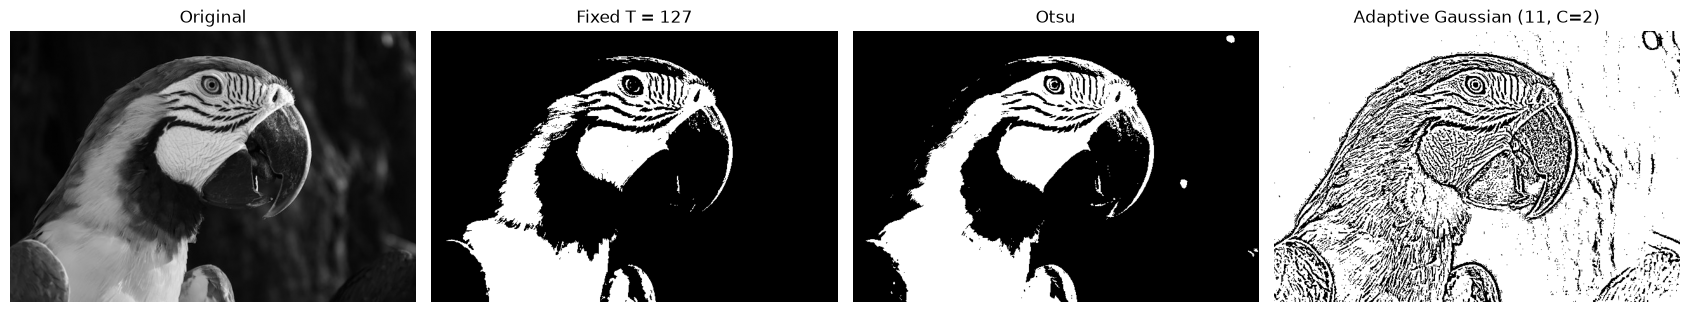

In [52]:
adaptive = cv.adaptiveThreshold(img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
show([img, binary, otsu, adaptive],
     ["Original", "Fixed T = 127", "Otsu", "Adaptive Gaussian (11, C=2)"], cols=4, figsize=(17, 4.2))

**When local thresholds help:** when lighting is uneven (shadows, gradients, scanned pages with a dark corner) a single global T turns whole regions fully black or white.
Adaptive thresholding computes T from each pixel's neighbourhood, so text/edges survive in both bright and dark areas. The cost: flat regions can fill with noise,
and results depend on `blockSize` and `C`.

## Summary explanations

- **Clipping:** forcing values outside 0–255 back to 0 or 255. It prevents wrap-around but destroys detail (many inputs map to one output).
- **Overflow:** `uint8` arithmetic wraps modulo 256 (200 + 100 → 44). We avoid it by computing in `int16`/`float32`, clipping, then converting back to `uint8`.
- **Brightness vs contrast:** brightness (β) adds a constant and shifts all intensities; contrast (α) scales the *differences* between intensities and widens or narrows the spread.
  Centering at 128 changes contrast without moving mid-gray.
- **Gamma convention:** s = 255 (r/255)^γ; γ < 1 brightens (expands darks), γ > 1 darkens; 0 and 255 never change.
- **Global vs local enhancement/thresholding:** global methods (equalizeHist, fixed/Otsu T) are fast and fine when lighting is uniform and the histogram is well separated;
  local methods (CLAHE, adaptive threshold) are better with uneven illumination, at the cost of more parameters and possible noise amplification.